<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/AI_Facial_Recognition_Privacy_Consent_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: Evaluating Privacy and Consent in an AI Facial Recognition System

**Objective:** Audit a fictional university facial-recognition attendance system. Identify personal and sensitive data, evaluate notice and consent, assess privacy/security risks, compare less intrusive attendance methods, and demonstrate privacy safeguards.

**Safety note:** All records are synthetic. No real student information, photographs, or biometric measurements are used. Biometric template IDs are dummy labels only. Risk ratings and retention limits are illustrative, not legal conclusions.

## Cell 1 — Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hmac, hashlib
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
print("Libraries imported successfully. Privacy audit is ready.")

Libraries imported successfully. Privacy audit is ready.


## Cell 2 — Create a synthetic student dataset

Generate 1,000 fictional student records. Attendance consent and consent for model training are separate because agreeing to attendance processing does not automatically authorize reuse of facial data for model improvement.

In [2]:
N = 1000
students = pd.DataFrame({
    "Student_ID": [f"STU{10000+i}" for i in range(N)],
    "Name": [f"Student_{i+1}" for i in range(N)],
    "Email": [f"student{i+1}@university.edu" for i in range(N)],
    "Department": rng.choice(["CSE","ECE","EEE","Mechanical","Civil"], N, p=[.35,.22,.15,.15,.13]),
    "Notice_Received": rng.choice([True,False], N, p=[.55,.45]),
    "Attendance_Consent": rng.choice([True,False], N, p=[.60,.40]),
    "Training_Consent": rng.choice([True,False], N, p=[.20,.80]),
    "Retention_Days": rng.integers(30,731,N),
    "Third_Party_Shared": rng.choice([True,False], N, p=[.35,.65]),
    "Unauthorized_Access": rng.choice([True,False], N, p=[.08,.92]),
    "Biometric_Template_ID": [f"FAKE_TEMPLATE_{i+1:05d}" for i in range(N)],
    "Attendance_Records": rng.integers(5,120,N)
})
print("Synthetic dataset created.")
print("Number of students:", len(students))
display(students.head(10))

Synthetic dataset created.
Number of students: 1000


,Student_ID,Name,Email,Department,Notice_Received,Attendance_Consent,Training_Consent,Retention_Days,Third_Party_Shared,Unauthorized_Access,Biometric_Template_ID,Attendance_Records
0,STU10000,Student_1,student1@university.edu,Mechanical,True,False,False,482,True,False,FAKE_TEMPLATE_00001,82
1,STU10001,Student_2,student2@university.edu,ECE,True,True,False,531,False,False,FAKE_TEMPLATE_00002,110
2,STU10002,Student_3,student3@university.edu,Mechanical,True,False,False,217,False,False,FAKE_TEMPLATE_00003,12
3,STU10003,Student_4,student4@university.edu,EEE,True,False,False,280,False,False,FAKE_TEMPLATE_00004,42
4,STU10004,Student_5,student5@university.edu,CSE,False,True,True,692,True,False,FAKE_TEMPLATE_00005,35
5,STU10005,Student_6,student6@university.edu,Civil,True,False,False,627,False,False,FAKE_TEMPLATE_00006,71
6,STU10006,Student_7,student7@university.edu,Mechanical,False,True,False,319,False,False,FAKE_TEMPLATE_00007,66
7,STU10007,Student_8,student8@university.edu,Mechanical,True,True,True,198,True,False,FAKE_TEMPLATE_00008,105
8,STU10008,Student_9,student9@university.edu,CSE,False,True,True,241,False,False,FAKE_TEMPLATE_00009,110
9,STU10009,Student_10,student10@university.edu,ECE,True,False,False,407,True,False,FAKE_TEMPLATE_00010,93


## Cell 3 — Task 1: Identify personal and sensitive information

Classify the information processed by the AI system. Facial images and biometric templates are particularly sensitive because they can be used to identify a person.

In [3]:
data_inventory = pd.DataFrame({
    "Information": ["Student name","Student ID","Email address","Facial image / biometric template","Attendance records","Entry/exit timestamps","Department","System access logs"],
    "Category": ["Personal information","Personal information","Personal information","Sensitive biometric information","Personal information","Personal information","Personal information","Security information"],
    "Purpose": ["Identify student","Link records","Contact student","Identify or verify student","Record attendance","Track campus movement","Administration","Monitor system use"],
    "Privacy_Risk": ["Identity exposure","Identity linkage","Phishing or misuse","Biometric misuse or breach","Behavioral profiling","Movement surveillance","Unnecessary profiling","Insider misuse"]
})
print("TASK 1 — PERSONAL AND SENSITIVE DATA INVENTORY")
display(data_inventory)
print("Data categories identified:", len(data_inventory))

TASK 1 — PERSONAL AND SENSITIVE DATA INVENTORY


,Information,Category,Purpose,Privacy_Risk
0,Student name,Personal information,Identify student,Identity exposure
1,Student ID,Personal information,Link records,Identity linkage
2,Email address,Personal information,Contact student,Phishing or misuse
3,Facial image / biometric template,Sensitive biometric information,Identify or verify student,Biometric misuse or breach
4,Attendance records,Personal information,Record attendance,Behavioral profiling
5,Entry/exit timestamps,Personal information,Track campus movement,Movement surveillance
6,Department,Personal information,Administration,Unnecessary profiling
7,System access logs,Security information,Monitor system use,Insider misuse


Data categories identified: 8


## Cell 4 — Task 2: Analyze notice and informed consent

Measure how many students received a notice, consented to attendance processing, and separately consented to model training. A meaningful notice should explain purpose, data collected, retention, recipients, risks and choices.

TASK 2 — NOTICE AND CONSENT ANALYSIS


,Measure,Students,Percentage
0,Received privacy notice,549,54.9
1,Did not receive privacy notice,451,45.1
2,Consented to attendance,621,62.1
3,Consented to model training,209,20.9
4,No recorded model-training consent,791,79.1


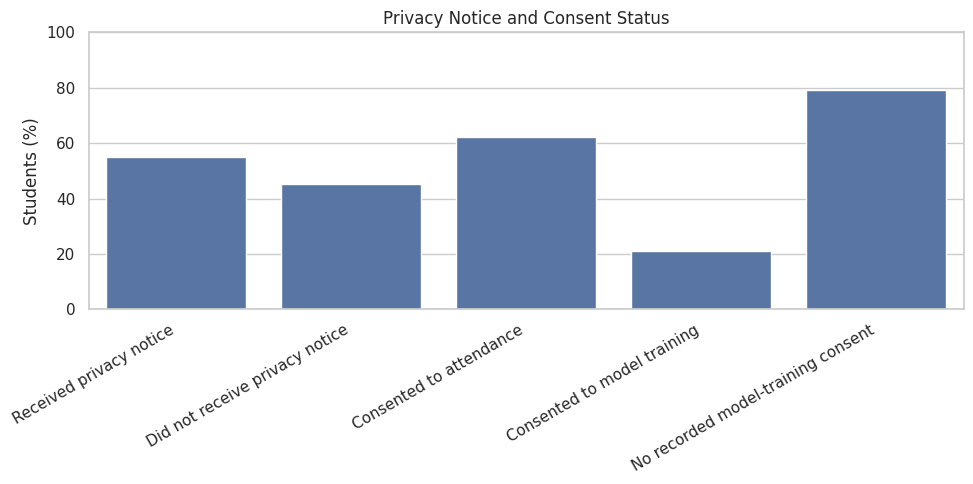

Finding: Consent for attendance and consent for model training are separate.
The university should not assume attendance consent authorizes model training.


In [4]:
consent_summary = pd.DataFrame({
    "Measure": ["Received privacy notice","Did not receive privacy notice","Consented to attendance","Consented to model training","No recorded model-training consent"],
    "Students": [
        students["Notice_Received"].sum(),
        (~students["Notice_Received"]).sum(),
        students["Attendance_Consent"].sum(),
        students["Training_Consent"].sum(),
        (~students["Training_Consent"]).sum()
    ]
})
consent_summary["Percentage"] = (consent_summary["Students"] / N * 100).round(2)
print("TASK 2 — NOTICE AND CONSENT ANALYSIS")
display(consent_summary)

plt.figure(figsize=(10,5))
sns.barplot(data=consent_summary, x="Measure", y="Percentage")
plt.title("Privacy Notice and Consent Status")
plt.ylabel("Students (%)")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.ylim(0,100)
plt.tight_layout()
plt.show()

print("Finding: Consent for attendance and consent for model training are separate.")
print("The university should not assume attendance consent authorizes model training.")

## Cell 5 — Task 3: Identify privacy, surveillance and security risks

Risk score = Likelihood × Impact. Both are rated from 1 (low) to 5 (very high). These are illustrative scenario ratings, not measured probabilities.

TASK 3 — PRIVACY AND SECURITY RISK REGISTER


,Risk,Likelihood,Impact,Explanation,Recommended_Control,Risk_Score,Risk_Level
4,Reuse without separate consent,5,5,Facial data may be reused for model improvement.,Obtain separate informed opt-in consent where ...,25,Critical
1,Excessive biometric retention,4,5,Data may be kept longer than necessary.,Set retention limits and automatic deletion.,20,Critical
0,Continuous student surveillance,4,4,Students may be monitored across campus.,Limit camera coverage and purpose.,16,High
2,Unauthorized employee access,3,5,Staff may view or export sensitive records.,Use role-based access and audit logs.,15,High
5,Biometric data breach,3,5,Stolen biometric information cannot easily be ...,"Use encryption, security testing and incident ...",15,High
3,Third-party data sharing,3,4,External vendors may process student data.,Assess vendors and restrict onward sharing.,12,Medium


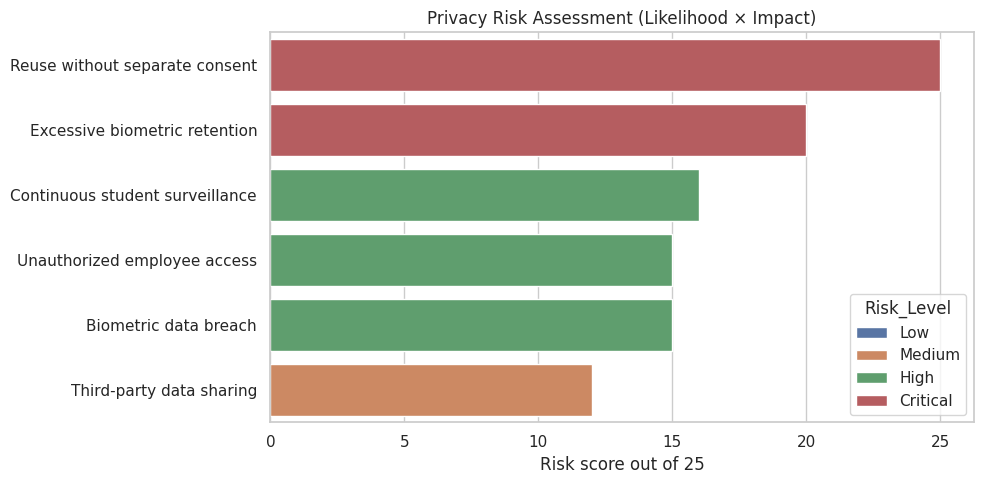

In [5]:
risk_register = pd.DataFrame({
    "Risk": ["Continuous student surveillance","Excessive biometric retention","Unauthorized employee access","Third-party data sharing","Reuse without separate consent","Biometric data breach"],
    "Likelihood": [4,4,3,3,5,3],
    "Impact": [4,5,5,4,5,5],
    "Explanation": [
        "Students may be monitored across campus.",
        "Data may be kept longer than necessary.",
        "Staff may view or export sensitive records.",
        "External vendors may process student data.",
        "Facial data may be reused for model improvement.",
        "Stolen biometric information cannot easily be replaced."
    ],
    "Recommended_Control": [
        "Limit camera coverage and purpose.",
        "Set retention limits and automatic deletion.",
        "Use role-based access and audit logs.",
        "Assess vendors and restrict onward sharing.",
        "Obtain separate informed opt-in consent where required.",
        "Use encryption, security testing and incident response."
    ]
})
risk_register["Risk_Score"] = risk_register["Likelihood"] * risk_register["Impact"]
risk_register["Risk_Level"] = pd.cut(
    risk_register["Risk_Score"], bins=[0,7,14,19,25],
    labels=["Low","Medium","High","Critical"]
)
print("TASK 3 — PRIVACY AND SECURITY RISK REGISTER")
display(risk_register.sort_values("Risk_Score", ascending=False))

plt.figure(figsize=(10,5))
sns.barplot(data=risk_register.sort_values("Risk_Score", ascending=False),
            x="Risk_Score", y="Risk", hue="Risk_Level", dodge=False)
plt.title("Privacy Risk Assessment (Likelihood × Impact)")
plt.xlabel("Risk score out of 25")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Cell 6 — Task 4: Evaluate necessity and proportionality

Compare facial recognition with less intrusive attendance options. Effectiveness, privacy risk and data sensitivity use illustrative scores from 1 to 5. Higher privacy-risk and sensitivity scores are worse.

TASK 4 — NECESSITY AND PROPORTIONALITY


,Method,Effectiveness,Privacy_Risk,Data_Sensitivity,Explanation,Privacy_Efficiency
4,Manual Attendance,3,1,1,Uses a teacher-maintained attendance list.,1.50
3,QR Code Attendance,4,2,1,Uses a temporary attendance code.,1.33
2,RFID Student Card,4,2,2,Uses a student card identifier.,1.00
0,Facial Recognition,5,5,5,Identifies students using facial biometrics.,0.50
1,Fingerprint Scanner,4,5,5,Uses fingerprint biometrics.,0.40


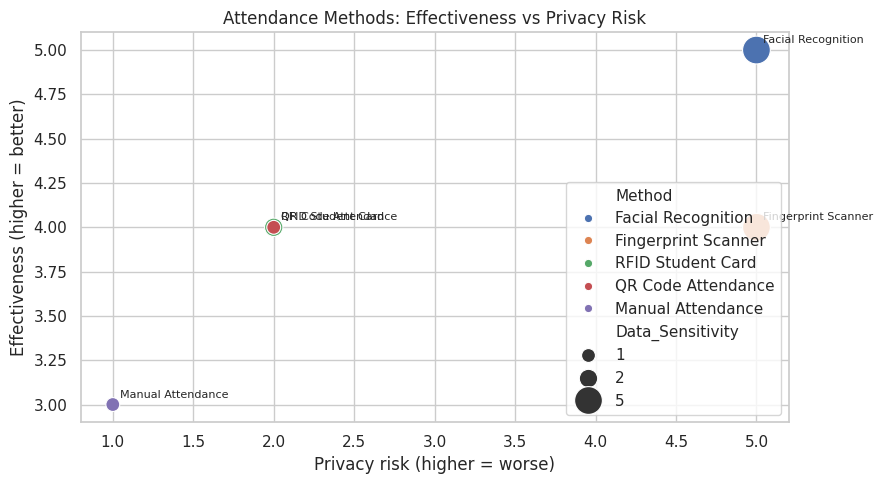

Finding: QR code or RFID may achieve attendance goals with lower biometric privacy risk.
The university should justify why a less intrusive method is insufficient.


In [6]:
method_comparison = pd.DataFrame({
    "Method": ["Facial Recognition","Fingerprint Scanner","RFID Student Card","QR Code Attendance","Manual Attendance"],
    "Effectiveness": [5,4,4,4,3],
    "Privacy_Risk": [5,5,2,2,1],
    "Data_Sensitivity": [5,5,2,1,1],
    "Explanation": [
        "Identifies students using facial biometrics.",
        "Uses fingerprint biometrics.",
        "Uses a student card identifier.",
        "Uses a temporary attendance code.",
        "Uses a teacher-maintained attendance list."
    ]
})
method_comparison["Privacy_Efficiency"] = (
    method_comparison["Effectiveness"] /
    (method_comparison["Privacy_Risk"] + method_comparison["Data_Sensitivity"])
).round(2)
print("TASK 4 — NECESSITY AND PROPORTIONALITY")
display(method_comparison.sort_values("Privacy_Efficiency", ascending=False))

plt.figure(figsize=(9,5))
sns.scatterplot(data=method_comparison, x="Privacy_Risk", y="Effectiveness",
                hue="Method", size="Data_Sensitivity", sizes=(100,400))
for _, r in method_comparison.iterrows():
    plt.annotate(r["Method"], (r["Privacy_Risk"], r["Effectiveness"]),
                 xytext=(5,5), textcoords="offset points", fontsize=8)
plt.title("Attendance Methods: Effectiveness vs Privacy Risk")
plt.xlabel("Privacy risk (higher = worse)")
plt.ylabel("Effectiveness (higher = better)")
plt.tight_layout()
plt.show()
print("Finding: QR code or RFID may achieve attendance goals with lower biometric privacy risk.")
print("The university should justify why a less intrusive method is insufficient.")

## Cell 7 — Task 5: Demonstrate privacy safeguards

Demonstrate masking, keyed-hash pseudonymization and role-based access. A keyed hash is not encryption and does not make data anonymous if the university can still link it to a student.

In [7]:
def mask_student_id(value):
    return value[:3] + "****"

DEMO_SECRET = b"colab-demo-secret-change-in-production"

def pseudonymize(value):
    return hmac.new(DEMO_SECRET, value.encode("utf-8"), hashlib.sha256).hexdigest()[:16]

protected_view = students[["Student_ID","Department","Attendance_Records"]].copy()
protected_view["Masked_ID"] = protected_view["Student_ID"].apply(mask_student_id)
protected_view["Pseudonymous_Token"] = protected_view["Student_ID"].apply(pseudonymize)
protected_view = protected_view.drop(columns=["Student_ID"])

print("TASK 5 — PRIVACY-PROTECTED REPORT VIEW")
display(protected_view.head(10))

permissions = {
    "Attendance_Staff": ["Student_ID","Attendance_Records"],
    "Security_Officer": ["Student_ID"],
    "AI_Developer": ["Pseudonymous_Token"],
    "Unauthorized_User": []
}

def check_access(role, field):
    return "ACCESS GRANTED" if field in permissions.get(role, []) else "ACCESS DENIED"

print("\nRole-based access examples:")
for role, field in [
    ("Attendance_Staff","Attendance_Records"),
    ("AI_Developer","Pseudonymous_Token"),
    ("AI_Developer","Student_ID"),
    ("Unauthorized_User","Biometric_Template_ID")
]:
    print(role, "requesting", field, ":", check_access(role, field))

TASK 5 — PRIVACY-PROTECTED REPORT VIEW


,Department,Attendance_Records,Masked_ID,Pseudonymous_Token
0,Mechanical,82,STU****,7fd6b059154a568e
1,ECE,110,STU****,a471402081345198
2,Mechanical,12,STU****,36b2d873f3b37868
3,EEE,42,STU****,aa8d63c637fa90fe
4,CSE,35,STU****,b924653b89f68386
5,Civil,71,STU****,727264ba72c18810
6,Mechanical,66,STU****,3caeb95a4058d51b
7,Mechanical,105,STU****,83062f554321dbea
8,CSE,110,STU****,4bc1a96900950ce6
9,ECE,93,STU****,18e0f6e1550bd477



Role-based access examples:
Attendance_Staff requesting Attendance_Records : ACCESS GRANTED
AI_Developer requesting Pseudonymous_Token : ACCESS GRANTED
AI_Developer requesting Student_ID : ACCESS DENIED
Unauthorized_User requesting Biometric_Template_ID : ACCESS DENIED


## Cell 8 — Analyze data retention

For demonstration only, assume a proposed maximum retention period of 90 days after the attendance purpose is completed. Compare the synthetic retention durations against this limit. A real retention schedule must be justified by purpose, policy and applicable law.

DATA RETENTION AUDIT
Proposed retention limit: 90 days


,Retention_Status,Students,Percentage
0,Exceeds proposed limit,914,91.4
1,Within proposed limit,86,8.6


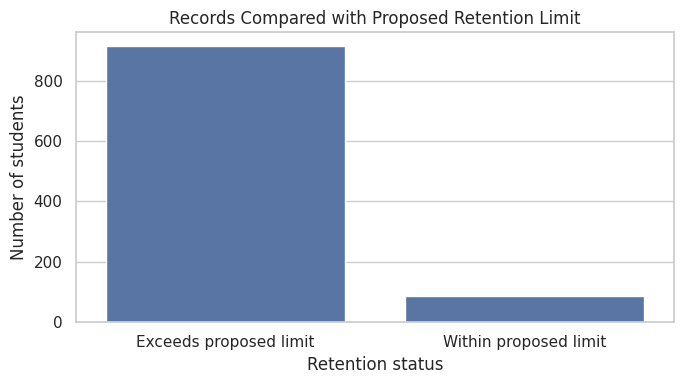

Recommendation: Delete or irreversibly anonymize data when its justified retention period ends.


In [8]:
RETENTION_LIMIT_DAYS = 90
students["Retention_Status"] = np.where(
    students["Retention_Days"] > RETENTION_LIMIT_DAYS,
    "Exceeds proposed limit",
    "Within proposed limit"
)
retention_summary = students["Retention_Status"].value_counts().rename_axis(
    "Retention_Status"
).reset_index(name="Students")
retention_summary["Percentage"] = (retention_summary["Students"] / N * 100).round(2)

print("DATA RETENTION AUDIT")
print("Proposed retention limit:", RETENTION_LIMIT_DAYS, "days")
display(retention_summary)

plt.figure(figsize=(7,4))
sns.countplot(data=students, x="Retention_Status")
plt.title("Records Compared with Proposed Retention Limit")
plt.xlabel("Retention status")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()
print("Recommendation: Delete or irreversibly anonymize data when its justified retention period ends.")

## Cell 9 — Final privacy audit and recommendations

Summarize the audit findings and create recommendations that directly answer the five assignment tasks.

In [9]:
audit_summary = pd.DataFrame({
    "Finding": [
        "Total fictional students",
        "Students without privacy notice",
        "Students without recorded training consent",
        "Records exceeding proposed retention limit",
        "Students flagged for third-party sharing",
        "Students flagged for unauthorized access"
    ],
    "Count": [
        len(students),
        (~students["Notice_Received"]).sum(),
        (~students["Training_Consent"]).sum(),
        (students["Retention_Days"] > RETENTION_LIMIT_DAYS).sum(),
        students["Third_Party_Shared"].sum(),
        students["Unauthorized_Access"].sum()
    ]
})
print("FINAL PRIVACY AUDIT SUMMARY")
display(audit_summary)

recommendations = pd.DataFrame({
    "Area": ["Notice and consent","Purpose limitation","Data minimization","Retention","Security","Third-party sharing","Alternative methods","Accountability"],
    "Recommendation": [
        "Provide a clear notice and obtain separate meaningful consent for model training where required.",
        "Use biometric data only for a clearly stated and justified purpose.",
        "Avoid retaining raw face images if a less sensitive method meets the purpose.",
        "Set and enforce a justified retention schedule and secure deletion.",
        "Use encryption, least-privilege access, audit logs and security testing.",
        "Assess vendors, restrict onward sharing and establish suitable data-processing agreements.",
        "Offer QR code, RFID or student-card attendance where suitable.",
        "Conduct privacy impact assessments, audits and provide complaint and review channels."
    ]
})
print("\nPRIVACY SAFEGUARD RECOMMENDATIONS")
display(recommendations)

print("\nCONCLUSION")
print("The simulated audit identifies gaps in notice, consent, retention transparency and access governance.")
print("The university should justify necessity, prefer less intrusive alternatives where effective,")
print("and apply data minimization, security, limited retention and accountability.")

FINAL PRIVACY AUDIT SUMMARY


,Finding,Count
0,Total fictional students,1000
1,Students without privacy notice,451
2,Students without recorded training consent,791
3,Records exceeding proposed retention limit,914
4,Students flagged for third-party sharing,391
5,Students flagged for unauthorized access,81



PRIVACY SAFEGUARD RECOMMENDATIONS


,Area,Recommendation
0,Notice and consent,Provide a clear notice and obtain separate mea...
1,Purpose limitation,Use biometric data only for a clearly stated a...
2,Data minimization,Avoid retaining raw face images if a less sens...
3,Retention,Set and enforce a justified retention schedule...
4,Security,"Use encryption, least-privilege access, audit ..."
5,Third-party sharing,"Assess vendors, restrict onward sharing and es..."
6,Alternative methods,"Offer QR code, RFID or student-card attendance..."
7,Accountability,"Conduct privacy impact assessments, audits and..."



CONCLUSION
The simulated audit identifies gaps in notice, consent, retention transparency and access governance.
The university should justify necessity, prefer less intrusive alternatives where effective,
and apply data minimization, security, limited retention and accountability.


## Cell 10 — Export the audit results

In [10]:
students.to_csv("Synthetic_University_Student_Data.csv", index=False)
data_inventory.to_csv("Personal_and_Sensitive_Data_Inventory.csv", index=False)
consent_summary.to_csv("Notice_and_Consent_Analysis.csv", index=False)
risk_register.to_csv("Privacy_Risk_Register.csv", index=False)
method_comparison.to_csv("Attendance_Method_Comparison.csv", index=False)
retention_summary.to_csv("Data_Retention_Audit.csv", index=False)
recommendations.to_csv("Privacy_Safeguard_Recommendations.csv", index=False)
print("All privacy audit CSV files saved successfully.")

All privacy audit CSV files saved successfully.


## Final conclusion

The case study demonstrates that facial recognition creates significant privacy risks when biometric information is collected, retained or reused without clear notice and meaningful consent. Attendance consent does not automatically authorize model-training reuse. The university should identify all personal and sensitive data, explain purposes and retention, restrict access, assess third-party processors, and delete data when no longer necessary.

Facial recognition should be used only where necessary and proportionate. QR-code, RFID or student-card attendance may achieve the same purpose with lower biometric privacy risks. Privacy by design, data minimization, security controls, transparency, student choice and regular audits are essential for responsible AI.

**Note:** This notebook uses synthetic data and illustrative risk scores. Outputs demonstrate an audit method; they do not establish actual university practices, legal compliance or real incident rates.